# Example of the aitlas toolbox in the context of semantic segmentation

This notebook showcases a machine learning example for the MSLCC dataset, using the Sentinel-2 images.

## Import the required packages

In [ ]:
from aitlas.datasets import MSLCCDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 1196


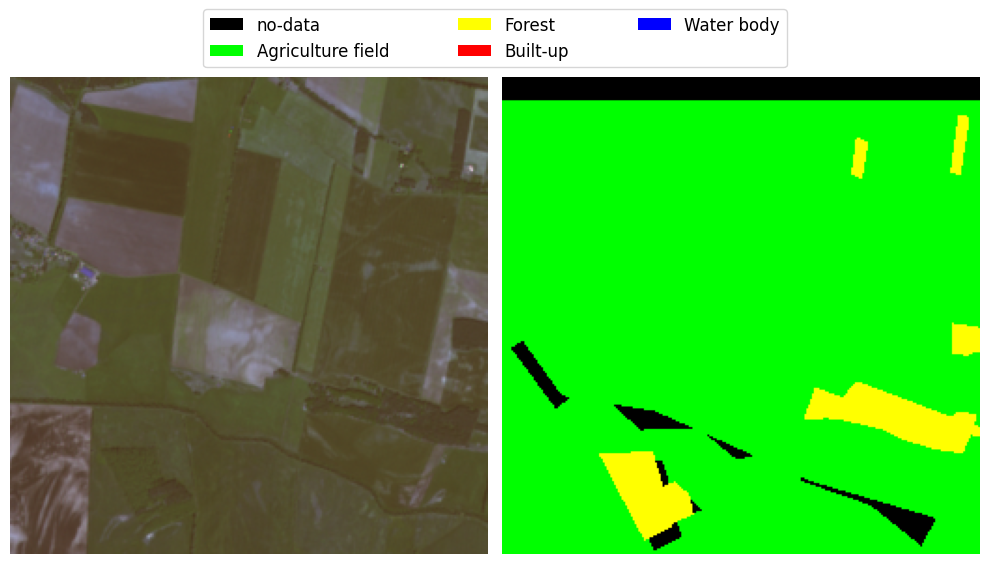

2025-09-03 08:26:23,293 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


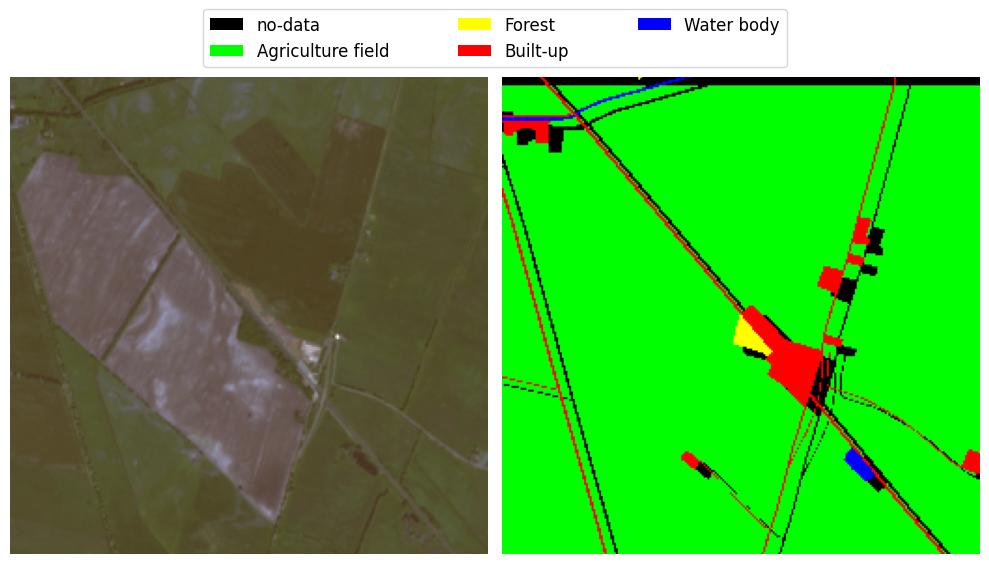

2025-09-03 08:26:23,500 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


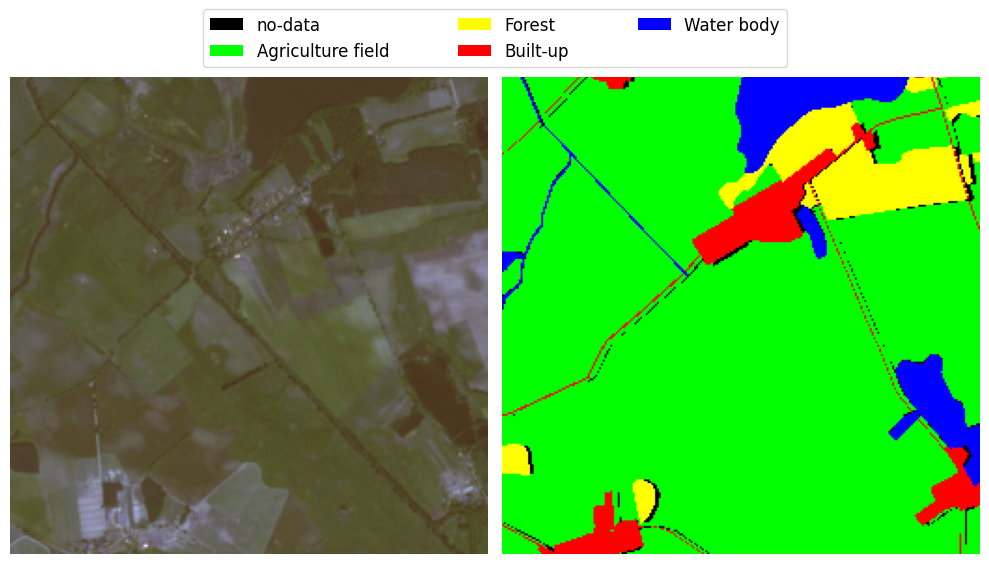

In [ ]:
dataset_config = {
    "data_dir": "./data/MSLCC/multi_sensor_landcover_classification",
    "selection": "s2"
}
dataset = MSLCCDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(700);

In [296]:
dataset.data_distribution_table()

,Number of pixels
no-data,3437920.0
Agriculture field,31364631.0
Forest,22251754.0
Built-up,18576023.0
Water body,2750728.0


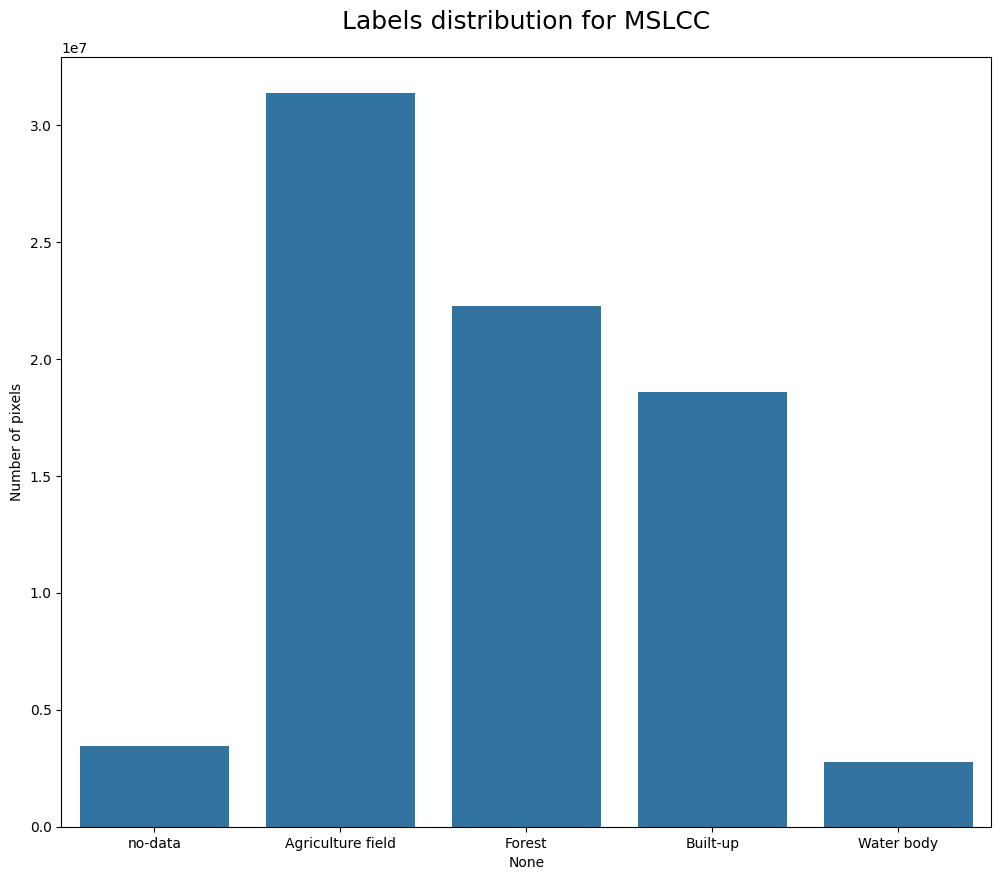

In [197]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/MSLCC/multi_sensor_landcover_classification",
    "selection": "s2",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = MSLCCDataset(train_dataset_config)
len(train_dataset)

957

## Create the model

In [ ]:
epochs = 20
model_directory = "./data/experiments/MSLCC"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [237]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-09-02 14:08:48,902 INFO Starting training.
training: 100%|██████████| 120/120 [00:10<00:00, 10.91it/s]
2025-09-02 14:08:59,951 INFO epoch: 1, time: 11, loss:  0.61644
testing on train set: 100%|██████████| 120/120 [00:04<00:00, 25.75it/s]
2025-09-02 14:09:06,608 INFO IOU:0.41411127843538675, IOU mean:0.25689909472390704, IOU per Class:[0.         0.48345731 0.31418763 0.48685054 0.        ]
training: 100%|██████████| 120/120 [00:10<00:00, 10.99it/s]
2025-09-02 14:09:17,532 INFO epoch: 2, time: 11, loss:  0.53319
testing on train set: 100%|██████████| 120/120 [00:04<00:00, 25.84it/s]
2025-09-02 14:09:22,189 INFO IOU:0.41606597555654173, IOU mean:0.2568630129545809, IOU per Class:[0.         0.48325926 0.31680503 0.48425077 0.        ]
training: 100%|██████████| 120/120 [00:11<00:00, 10.89it/s]
2025-09-02 14:09:33,209 INFO epoch: 3, time: 11, loss:  0.48576
testing on train set: 100%|██████████| 120/120 [00:04<00:00, 25.58it/s]
2025-09-02 14:09:37,916 INFO IOU:0.42574759586326555, I

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/MSLCC/multi_sensor_landcover_classification",
    "selection": "s2",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = MSLCCDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/MSLCC/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

120


2025-09-02 14:14:19,622 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MSLCC/checkpoint.pth.tar
2025-09-02 14:14:20,089 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MSLCC/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 30/30 [00:01<00:00, 23.45it/s]


[{'IOU': 0.33484189312244117,
  'IOU mean': 0.1556437172793269,
  'IOU per Class': array([0.        , 0.47893719, 0.2314978 , 0.0677836 , 0.        ])}]

## Predictions

2025-09-02 14:21:56,055 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MSLCC/checkpoint.pth.tar
2025-09-02 14:21:56,413 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MSLCC/checkpoint.pth.tar at epoch 21
2025-09-02 14:21:56,624 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-02 14:21:56,742 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


119


2025-09-02 14:21:56,865 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


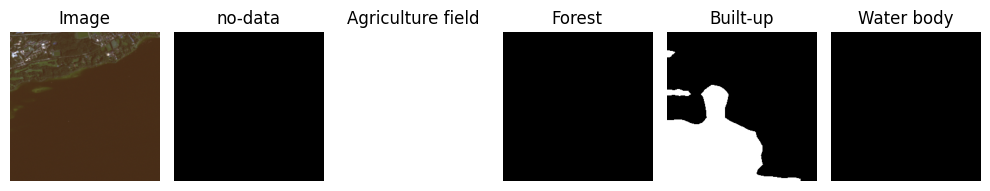

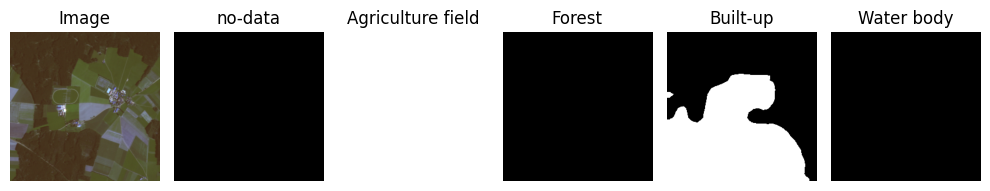

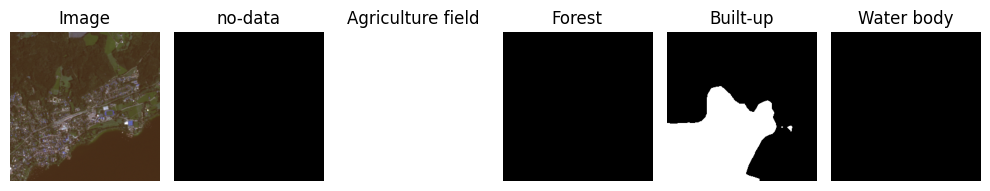

In [ ]:
model_path = "./data/experiments/MSLCC/checkpoint.pth.tar"
labels = ["no-data","Agriculture field","Forest","Built-up","Water body"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/MSLCC/multi_sensor_landcover_classification",
    "selection": "s2",
    "mode": "test",
}
test_dataset = MSLCCDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[20][0]
fig = model.predict_masks(image, labels, transform)